<a href="https://colab.research.google.com/github/pdf1802/f1-data-science/blob/main/notebooks/degradation_by_circuit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 1 V3.2 — How hard is today on tyres?

**The problem.** Every tool that compares strategies had the same blind spot: one stop looked too good.
The Race Engineer said *NO MORE STOPS* in Bahrain, the Stint Optimizer recommended a one-stop where nobody has
one-stopped in four seasons. One root cause: **Module 1 knew the circuit only as a label**, and its trees flattened
the differences in tyre degradation between circuits.

**What this notebook does** — and the ideas it teaches:

| Step | Idea |
|---|---|
| 1. Measure degradation per race | fixed-effects regression, bootstrap over the right unit |
| 2. Compare with what the model believed | diagnose a model on the quantity the *decision* uses, not on MAE |
| 3. Circuit, or the day? | random effects, shrinkage (empirical Bayes) |
| 4. Give the model the rate as an input | train with what you know afterwards, serve with what you know before |
| 5. Test the model as it is served | a sanity check can fail because of the check |
| 6. The day is uncertain → so is the simulation | propagating a parameter's uncertainty |
| 7. Update during the race | Bayesian updating, calibration of an uncertainty |
| 8. Validate the decision | one stop or two, against what the field really did |

**Code:** [`tools/degradation.py`](../tools/degradation.py), [`tools/training.py`](../tools/training.py),
[`tools/race_engine.py`](../tools/race_engine.py), [`tools/stint_optimizer.py`](../tools/stint_optimizer.py).
Every step shows the real source and runs it on the 35 usable dry races of `data/laps_2022_2025.parquet`
(wet races are out, and so is Miami 2025: its tyre data in the cache is a placeholder — the same compound sequence
for 15 cars — found by an independent review and now caught by `training.broken_races`).

In [1]:
# Setup — local checkout or Colab. Data and models are not in git (see the README: Data, Train the models).
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:                       # Colab: clone the repo, models + Parquet from Drive
    if not os.path.exists("/content/f1-data-science"):
        subprocess.run(["git", "clone", "-q", "https://github.com/pdf1802/f1-data-science", "/content/f1-data-science"], check=True)
    os.chdir("/content/f1-data-science")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("F1_MODEL_DIR", "/content/drive/MyDrive/f1_models")
    os.environ.setdefault("F1_LAPS", "/content/drive/MyDrive/f1_data/laps_2022_2025.parquet")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, display
from tools import shared, training

def show(obj):
    """Display the real source of a function / class from tools/ — the code the dashboard runs."""
    return Code(inspect.getsource(obj), language="python")

LAPS_ALL = pd.read_parquet(os.environ.get("F1_LAPS", os.path.join(ROOT, "data", "laps_2022_2025.parquet")))
LAPS, WET = training.dry_races(LAPS_ALL)
print(f"Models: {os.path.relpath(shared.resolve_model_dir(), ROOT)}/")
print(f"Laps: {LAPS_ALL.groupby(['Season', 'Race']).ngroups} races, {len(LAPS_ALL):,} laps "
      f"· {LAPS.groupby(['Season', 'Race']).ngroups} dry races used")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})

Models: models/
Laps: 43 races, 44,526 laps · 35 dry races used


In [2]:
from tools import degradation, race_engine as eng, stint_optimizer
from tools.degradation import race_physics, fit_prior, live_estimate
COL = {"SOFT": "#DA291C", "MEDIUM": "#E0B000", "HARD": "#666666"}

## 1. Measure first: the degradation rate of each race

A lap time is the sum of many things. To isolate the tyre we write, for the clean laps of **one race**:

$$\text{LapTime} = \alpha_{driver} \;-\; \varphi\cdot\text{Lap} \;+\; \beta_{compound} \;+\; \gamma\cdot\text{TyreAge} \;+\; \varepsilon$$

- $\alpha_{driver}$ — a constant per driver (car + driver pace). *Fixed effects*: we never estimate it, we subtract
  each driver's mean from every variable, which removes it exactly.
- $\varphi$ — seconds gained per lap from burning fuel (and the track rubbering in).
- $\gamma$ — **the degradation rate: seconds lost per lap of tyre age.** This is the number we are after.

$\gamma$ and $\varphi$ can be told apart only because tyre age *resets* at a pit stop and the lap number does not.
Hold on to that: it comes back in step 7.

In [3]:
show(degradation.stint_laps)

def stint_laps(laps: pd.DataFrame, clean_air_gap: float | None = CLEAN_AIR_GAP,
               max_tyre_age: int = 35) -> pd.DataFrame:
    """
    The laps that show tyre behaviour: green flag, dry compound, no in/out laps, not lap 1,
    in clean air (traffic hides pace), within 3 s of the driver's median (no mistakes).
    Adds LT (s), race ("2023 Bahrain Grand Prix"), key (race + driver) and circuit.
    """
    from tools.training import _seconds, add_gap_ahead
    d = add_gap_ahead(laps) if clean_air_gap is not None else laps.copy()
    d["LT"] = _seconds(d["LapTime"])
    keep = (d["Compound"].isin(DRY) & (d["TrackStatus"].astype(str) == "1")
            & d["PitInTime"].isna() & d["PitOutTime"].isna() & (d["LapNumber"] > 1)
            & d["TyreLife"].between(2, max_tyre_age) & d["LT"].between(60, 150))
    if clean_air_gap is not None:
        keep &= ((d["PosStart"] == 1) | (d["GapAheadStart"] > clean_air_gap)).fillna(False).astype(bool)
    d = d[keep].copy()
    d["race"] = d["Season"].astype(str) + " " + d["Race"].astype(str)
    d["key"] = d["race"] + " " + d["Driver"].astype(str)
    d = d[(d["LT"] - d.groupby("key")["LT"].transform("median")).abs() < 3]
    d["circuit"] = d["Race"].map(circuit_name)
    return d

In [4]:
show(degradation._fit_race)

def _fit_race(g: pd.DataFrame) -> tuple[float, float]:
    """(degradation γ, fuel+evolution φ) of one race by least squares with driver fixed effects."""
    Xd, yd = _design(g)
    beta, *_ = np.linalg.lstsq(Xd, yd, rcond=None)
    return float(beta[3]), float(-beta[0])

**How sure are we of each race's $\gamma$?** The usual standard error assumes independent laps. They are not:
twenty laps of one driver share his car, his traffic, his tyre set. The independent unit is the **driver**, so the
bootstrap resamples *drivers* (with all their laps), refits, and takes the spread of the 200 results.

In [5]:
show(degradation.race_physics)

def race_physics(laps: pd.DataFrame, n_boot: int = 200, seed: int = 0) -> pd.DataFrame:
    """
    One row per race: deg (γ), fuel (φ) and their standard errors from a bootstrap over
    DRIVERS (laps of one driver are not independent; drivers are the unit to resample).
    A race where everyone stopped at the same time has age ≈ lap − constant, so γ and φ
    cannot be told apart: the bootstrap shows it as a large standard error.
    """
    d = stint_laps(laps)
    rng = np.random.default_rng(seed)
    rows = []
    for race, g in d.groupby("race"):
        if g["Driver"].nunique() < 4 or len(g) < 80:
            continue
        deg, fuel = _fit_race(g)
        drivers = g["Driver"].unique()
        parts = {p: g[g["Driver"] == p] for p in drivers}
        boots = []
        for _ in range(n_boot):
            pick = rng.choice(drivers, len(drivers))
            boots.append(_fit_race(pd.concat([parts[p].assign(key=str(i)) for i, p in enumerate(pick)])))
        boots = np.array(boots)
        rows.append({"race": race, "circuit": g["circuit"].iloc[0], "n_laps": len(g), "deg": deg,
                     "deg_se": float(boots[:, 0].std()), "fuel": fuel, "fuel_se": float(boots[:, 1].std())})
    return pd.DataFrame(rows).set_index("race")

In [6]:
P = race_physics(LAPS)                    # ~1–2 min: 36 races × 200 bootstrap fits
print(f"{len(P)} races · γ from {P.deg.min():.3f} to {P.deg.max():.3f} s/lap · median standard error {P.deg_se.median():.3f}")
by_circuit = P.groupby("circuit").agg(races=("deg", "size"), deg_mean=("deg", "mean"), deg_min=("deg", "min"),
                                      deg_max=("deg", "max"), fuel=("fuel", "mean")).sort_values("deg_mean")
by_circuit.round(3)

35 races · γ from 0.019 to 0.162 s/lap · median standard error 0.007


,races,deg_mean,deg_min,deg_max,fuel
circuit,,,,,
British,2,0.025,0.025,0.025,0.058
Azerbaijan,3,0.031,0.021,0.041,0.073
Miami,2,0.033,0.029,0.037,0.056
Saudi Arabian,3,0.038,0.025,0.050,0.081
Italian,4,0.047,0.019,0.065,0.052
Singapore,3,0.047,0.030,0.059,0.048
Australian,2,0.052,0.044,0.061,0.079
Monaco,2,0.058,0.030,0.086,0.078
Austrian,2,0.061,0.056,0.066,0.029


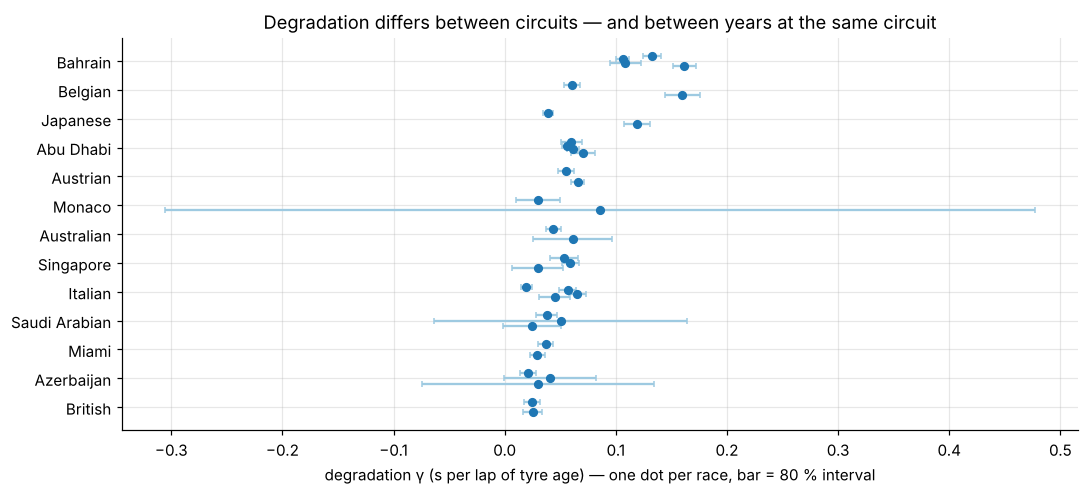

In [7]:
order = list(by_circuit.index)
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, c in enumerate(order):
    g = P[P.circuit == c]
    ax.errorbar(g.deg, np.full(len(g), i) + np.linspace(-0.18, 0.18, len(g)), xerr=1.28 * g.deg_se, fmt="o",
                color="#1f77b4", ecolor="#9ecae1", capsize=2, ms=5)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("degradation γ (s per lap of tyre age) — one dot per race, bar = 80 % interval")
ax.set_title("Degradation differs between circuits — and between years at the same circuit")
plt.tight_layout(); plt.show()

**Reading it.** Bahrain degrades four to five times faster than Silverstone or Baku. But look at the rows with several
dots: the same circuit moves a lot from one year to the next (Spa, Suzuka, Bahrain). Keep that in mind for step 3.

## 2. What did the model believe?

Module 1 V3.1 was `LapDelta = f(compound, tyre age, circuit)`. Its error on unseen races was fine. But a strategy
tool does not use "the error": it uses **the slope of the curve with tyre age** — that is what decides whether a
second stop pays for itself. So that is what we check: train V3.1 here, read the slope it implies at each circuit
(MEDIUM and HARD, age 2 → 25), and put it next to the measurement.

spread between circuits (sd): measured 0.030 · V3.1 0.010


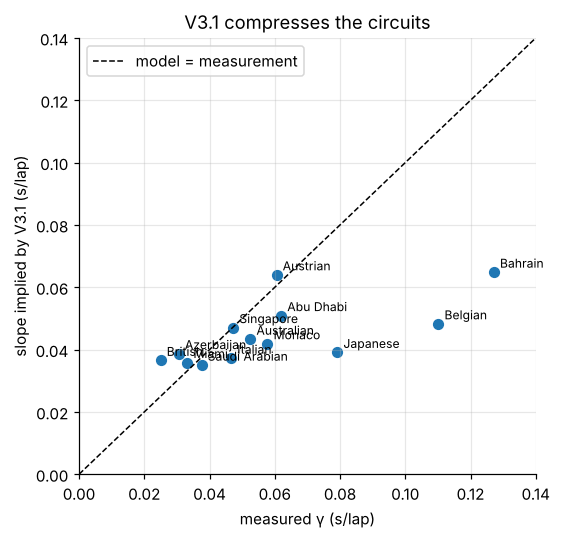

,measured,V3.1 implied
circuit,,
British,0.025,0.037
Azerbaijan,0.031,0.039
Miami,0.033,0.036
Saudi Arabian,0.038,0.035
Italian,0.047,0.037
Singapore,0.047,0.047
Australian,0.052,0.043
Monaco,0.058,0.042
Austrian,0.061,0.064


In [8]:
circuits = training.circuit_list(LAPS)
F31 = ["CompoundEncoded", "TyreLife", "CircuitEncoded"]
lap31, _ = training.build_lap_dataset(LAPS, circuits=circuits)
m31 = training.make_lap_model(features=F31).fit(lap31[F31], lap31["LapDelta"])

def implied_slope(predict, circuit_idx, **cols):
    X = pd.DataFrame([{"CompoundEncoded": c, "TyreLife": a, "CircuitEncoded": float(circuit_idx)}
                      for c in (1, 2) for a in (2, 25)])
    for k, v in cols.items():
        X[k] = v(X) if callable(v) else v
    p = predict(X)
    return float(((p[1] - p[0]) + (p[3] - p[2])) / 2 / 23)

cmp = by_circuit[["deg_mean"]].rename(columns={"deg_mean": "measured"})
cmp["V3.1 implied"] = [implied_slope(lambda X: m31.predict(X[F31]), circuits.index(c)) for c in cmp.index]
print(f"spread between circuits (sd): measured {cmp.measured.std():.3f} · V3.1 {cmp['V3.1 implied'].std():.3f}")
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(cmp.measured, cmp["V3.1 implied"], s=40)
for c, r in cmp.iterrows():
    ax.annotate(c, (r.measured, r["V3.1 implied"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
lim = [0, 0.14]; ax.plot(lim, lim, "k--", lw=1, label="model = measurement"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("measured γ (s/lap)"); ax.set_ylabel("slope implied by V3.1 (s/lap)"); ax.legend()
ax.set_title("V3.1 compresses the circuits"); plt.tight_layout(); plt.show()
cmp.round(3)

**Diagnosis.** The model's circuits are squeezed into a narrow band: gentle circuits a little too harsh, harsh
circuits far too gentle (Bahrain about half of what was measured). Nothing is "broken": shallow, regularised trees
average over neighbours, and a circuit is one label with few stints behind it. But on the quantity that decides
strategy, the model was wrong where it mattered most.

> **Lesson.** A model can pass its error metric and fail its job. Find the quantity the decision depends on and
> check *that*.

## 3. Circuit — or the day?

Before fixing it: is degradation a property of the circuit? If it were, a per-circuit number would do. The data
says otherwise, so we model both levels:

$$\gamma_{race} \sim N(\mu_{circuit},\ \sigma_{race}^2) \qquad\qquad \mu_{circuit} \sim N(\mu,\ \sigma_{circuit}^2)$$

A race's rate is drawn around its circuit's; the circuits are drawn around the field. This is a **random-effects
model**; the three numbers ($\mu$, $\sigma_{circuit}$, $\sigma_{race}$) are fitted by maximum likelihood, taking
each race's own measurement error into account.

In [9]:
show(degradation._fit_random_effects)

def _fit_random_effects(P: pd.DataFrame) -> tuple[float, float, float]:
    """ML estimates of (global mean, between-circuit variance, race-to-race variance)."""
    from scipy.optimize import minimize
    groups = [(g["deg"].to_numpy(), g["deg_se"].to_numpy() ** 2) for _, g in P.groupby("circuit")]

    def nll(theta):
        mu, tau2, sig2 = theta[0], np.exp(theta[1]), np.exp(theta[2])
        out = 0.0
        for d, s2 in groups:                       # races of a circuit share its effect: cov = tau2
            S = np.diag(sig2 + s2) + tau2
            r = d - mu
            out += 0.5 * (np.linalg.slogdet(S)[1] + r @ np.linalg.solve(S, r))
        return out

    v = max(float(P["deg"].var()), 1e-6)
    res = minimize(nll, [float(P["deg"].mean()), np.log(v / 2), np.log(v / 2)], method="Nelder-Mead",
                   options={"xatol": 1e-7, "fatol": 1e-9, "maxiter": 5000})
    return float(res.x[0]), float(np.exp(res.x[1])), float(np.exp(res.x[2]))

In [10]:
show(degradation.fit_prior)

def fit_prior(P: pd.DataFrame) -> dict:
    """
    race_physics table → the degradation model as a plain dict (saved as degradation.json):

        global, circuit_sd, race_sd      the random-effects fit
        circuits {name: γ}               each circuit's estimate, shrunk to `global`
        races {race: γ}                  each race's own γ, shrunk to its circuit by its precision
                                         (the value Module 1 is trained with)
        fuel {global, races {race: φ}}   fuel + track evolution per race, shrunk the same way
    """
    if len(P) < 3 or P["circuit"].nunique() < 2:                 # not enough races to split the variance
        mu = float(np.average(P["deg"], weights=1 / P["deg_se"].clip(lower=1e-3) ** 2)) if len(P) else 0.058
        tau2 = sig2 = 0.025 ** 2
    else:
        mu, tau2, sig2 = _fit_random_effects(P)
    circuits, circuit_sd = {}, {}
    for c, g in P.groupby("circuit"):
        w = 1.0 / (sig2 + g["deg_se"].to_numpy() ** 2)
        m, V = float((w * g["deg"]).sum() / w.sum()), float(1.0 / w.sum())
        circuits[c] = float(np.clip((m / V + mu / tau2) / (1 / V + 1 / tau2), *DEG_RANGE))
        # what a NEW race here can be: year-to-year spread + how well the circuit's own mean is known
        circuit_sd[c] = float(np.sqrt(sig2 + 1.0 / (1 / V + 1 / tau2)))
    s2 = P["deg_se"].clip(lower=1e-4) ** 2
    prior = P["circuit"].map(circuits)
    races = ((P["deg"] / s2 + prior / sig2) / (1 / s2 + 1 / sig2)).clip(*DEG_RANGE)

    f2 = P["fuel_se"].clip(lower=1e-4) ** 2
    f_mu, f_tau2 = _fit_spread(P["fuel"].to_numpy(), f2.to_numpy()) if len(P) > 1 else (0.055, 1e-4)
    fuel = (P["fuel"] / f2 + f_mu / f_tau2) / (1 / f2 + 1 / f_tau2)
    return {"global": float(np.clip(mu, *DEG_RANGE)), "circuit_sd": float(np.sqrt(tau2)),
            "race_sd": float(np.sqrt(sig2)), "circuits": circuits, "circuit_pred_sd": circuit_sd,
            "races": {r: float(v) for r, v in races.items()},
            "fuel": {"global": f_mu, "sd": float(np.sqrt(f_tau2)), "races": {r: float(v) for r, v in fuel.items()}},
            "n_races": int(len(P))}

global mean μ = 0.058 s/lap
between circuits   σ_circuit = 0.026
year to year, same circuit   σ_race = 0.024


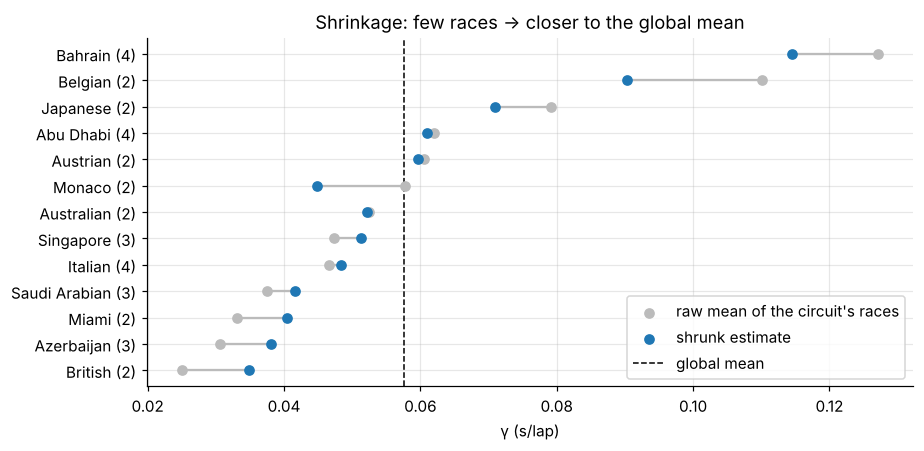

,races,raw mean,shrunk
circuit,,,
British,2,0.025,0.035
Azerbaijan,3,0.031,0.038
Miami,2,0.033,0.040
Saudi Arabian,3,0.038,0.042
Italian,4,0.047,0.048
Singapore,3,0.047,0.051
Australian,2,0.052,0.052
Monaco,2,0.058,0.045
Austrian,2,0.061,0.060


In [11]:
prior = fit_prior(P)
print(f"global mean μ = {prior['global']:.3f} s/lap")
print(f"between circuits   σ_circuit = {prior['circuit_sd']:.3f}")
print(f"year to year, same circuit   σ_race = {prior['race_sd']:.3f}")
shr = by_circuit[["races", "deg_mean"]].rename(columns={"deg_mean": "raw mean"})
shr["shrunk"] = pd.Series(prior["circuits"])
fig, ax = plt.subplots(figsize=(8.5, 4.2))
y = np.arange(len(shr))
ax.hlines(y, shr["raw mean"], shr["shrunk"], color="#bbbbbb")
ax.scatter(shr["raw mean"], y, label="raw mean of the circuit's races", color="#bbbbbb", zorder=3)
ax.scatter(shr["shrunk"], y, label="shrunk estimate", color="#1f77b4", zorder=3)
ax.axvline(prior["global"], color="k", ls="--", lw=1, label="global mean")
ax.set_yticks(y); ax.set_yticklabels([f"{c} ({n})" for c, n in zip(shr.index, shr.races)])
ax.set_xlabel("γ (s/lap)"); ax.legend(loc="lower right"); ax.set_title("Shrinkage: few races → closer to the global mean")
plt.tight_layout(); plt.show()
shr.round(3)

**Two findings.**

1. **The year matters as much as the circuit.** $\sigma_{race}$ is as large as $\sigma_{circuit}$: before a race,
   knowing the circuit tells you the degradation only to within about ±0.024 s/lap. No per-circuit constant can do
   better — the fix must carry **uncertainty**, and must be able to **learn during the race**.
2. **Shrinkage.** A circuit with two races has a noisy average. The best estimate is a weighted mean of that
   average and the global mean, the weights being how much each is worth:
   $\hat\mu_c = \dfrac{\bar\gamma_c / V_c + \mu / \sigma_{circuit}^2}{1/V_c + 1/\sigma_{circuit}^2}$.
   Bahrain (four races, all high) barely moves; Spa (two races, far apart) is pulled in. (A circuit's own average
   weighs each race by how precisely it was measured — Monaco's two races disagree and the better-measured one
   counts more, which is why its estimate is not between the plain mean and the global one.) This is *empirical Bayes*:
   the prior ($\mu$, $\sigma_{circuit}$) is itself estimated from the data.

## 4. The fix: give the model the rate

Instead of asking the trees to *infer* degradation from a label, we hand it to them:

`LapDelta = f(compound, tyre age, circuit, DegRate, Wear)` with `Wear = DegRate × tyre age`, monotone in tyre age and in Wear.

- **Training:** each race's laps carry **that race's own** rate (shrunk towards its circuit by how precisely it was
  measured). The model learns "at this rate, tyres age like this".
- **Serving:** before a race we do not know its rate, so we pass the **circuit's estimate**; during the race, the
  **live estimate** (step 7); for a what-if, any value.

The fuel correction also became per race (the $\varphi$ of step 1), instead of one constant for all.

In [12]:
show(training.fit_lap_pipeline)

def fit_lap_pipeline(dry: pd.DataFrame, circuits: list[str], n_boot: int = 200,
                     physics: pd.DataFrame | None = None, race_table: pd.DataFrame | None = None) -> dict:
    """
    Everything Module 1 needs, in order (used by train_models and by the leave-one-race-out
    backtest, so both run the same pipeline):
        race physics → degradation prior → dataset (per-race fuel, DegRate) → model → tail.
    """
    from tools import degradation
    if race_table is None:                       # each race is fitted on its own laps only, so a table
        race_table = degradation.race_physics(dry, n_boot=n_boot)    # computed once can be reused minus a race
    prior = degradation.fit_prior(race_table)
    physics = estimate_tyre_physics(dry) if physics is None else physics
    lap_df, enc = build_lap_dataset(dry, fuel_s_per_lap=degradation.fuel_map(prior), circuits=circuits,
                                    deg_rates={**prior["races"], "_default": prior["global"]})
    model = make_lap_model().fit(lap_df[LAP_MODEL_FEATURES], lap_df["LapDelta"])
    tail = deg_tail(lap_df, physics, ref_deg=prior["global"])
    young_soft = lap_df[(lap_df["CompoundEncoded"] == 0) & (lap_df["TyreLife"] <= 4)]
    counts = young_soft["Race"].astype(str).map(circuit_name).value_counts()
    prior["young_soft_laps"] = {c: int(counts.get(c, 0)) for c in circuits}     # where the SOFT's fresh pace is seen
    return {"model": model, "encoder": enc, "lap_df": lap_df, "tail": tail, "prior": prior,
            "race_table": race_table, "physics": physics}

In [13]:
fit = training.fit_lap_pipeline(LAPS, circuits, race_table=P)
model, lap_df, tail = fit["model"], fit["lap_df"], fit["tail"]
ev = training.evaluate_lap_model(lap_df, physics=P)
print(f"laps: {len(lap_df):,} · features: {training.LAP_MODEL_FEATURES}")
print(f"MAE on unseen races (GroupKFold, held-out races served with their circuit's prior): {ev['grouped_MAE']:.3f} s")
print(f"MAE of 'predict the median':                                                        {ev['predict_median_MAE']:.3f} s")

laps: 17,061 · features: ['CompoundEncoded', 'TyreLife', 'CircuitEncoded', 'DegRate', 'Wear']
MAE on unseen races (GroupKFold, held-out races served with their circuit's prior): 0.609 s
MAE of 'predict the median':                                                        0.664 s


**The honest test: leave one race out, look at the slope.** For every race: refit the prior and both models without
it, then ask each model for the slope at that circuit — V3.2 served with the prior a strategist would have had
before the race. Compare with the rate the race then showed.

V3.1: slope error (MAE) 0.0248 s/lap · calibration slope 1.26 (1 = a predicted difference between circuits is a real difference of the same size) · Bahrain 0.065 (measured 0.127)
V3.2: slope error (MAE) 0.0219 s/lap · calibration slope 0.83 (1 = a predicted difference between circuits is a real difference of the same size) · Bahrain 0.105 (measured 0.127)


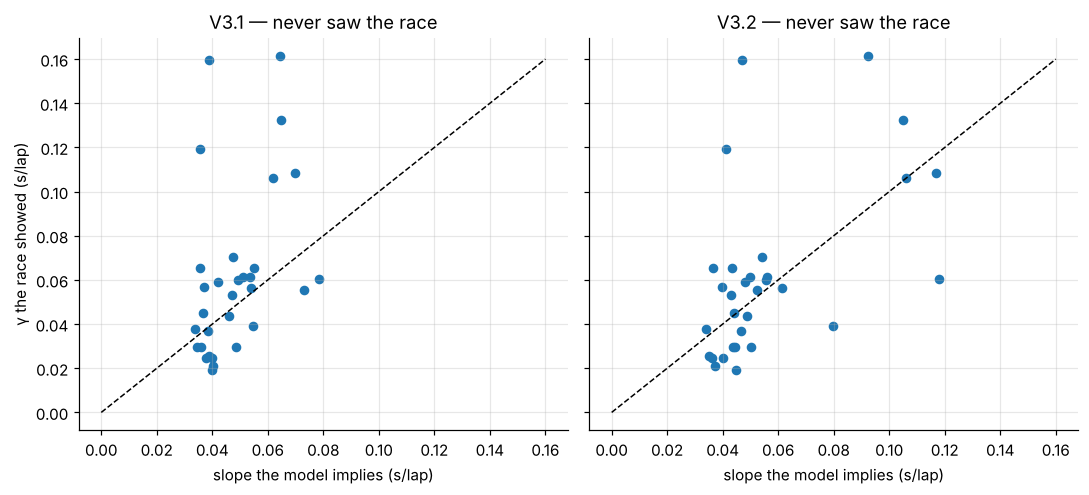

In [14]:
F32 = training.LAP_MODEL_FEATURES
rows = []
for race in P.index:                                             # ~3 min: 36 × 2 fits
    pr = fit_prior(P.drop(race))
    c = P.loc[race, "circuit"]
    g0 = pr["circuits"].get(c, pr["global"])                     # what was knowable before the race
    tr31, tr32 = lap31[lap31.Group != race], None
    d32, _ = training.build_lap_dataset(LAPS[(LAPS.Season.astype(str) + " " + LAPS.Race) != race],
                                        fuel_s_per_lap=degradation.fuel_map(pr), circuits=circuits,
                                        deg_rates={**pr["races"], "_default": pr["global"]})
    a = training.make_lap_model(features=F31).fit(tr31[F31], tr31["LapDelta"])
    b = training.make_lap_model().fit(d32[F32], d32["LapDelta"])
    k = circuits.index(c)
    rows.append({"race": race, "circuit": c, "true": P.loc[race, "deg"], "se": P.loc[race, "deg_se"], "prior": g0,
                 "V3.1": implied_slope(lambda X: a.predict(X[F31]), k),
                 "V3.2": implied_slope(lambda X: b.predict(X[F32]), k, DegRate=g0, Wear=lambda X: g0 * X.TyreLife)})
loro = pd.DataFrame(rows).set_index("race")
ok = loro[loro.se < 0.03]                                         # races whose own rate is well measured
for m in ("V3.1", "V3.2"):
    slope = np.polyfit(ok[m], ok["true"], 1)[0]
    print(f"{m}: slope error (MAE) {np.abs(ok[m] - ok['true']).mean():.4f} s/lap · calibration slope {slope:.2f} "
          f"(1 = a predicted difference between circuits is a real difference of the same size) · "
          f"Bahrain {loro[loro.circuit == 'Bahrain'][m].mean():.3f} (measured {loro[loro.circuit == 'Bahrain']['true'].mean():.3f})")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, m in zip(axes, ("V3.1", "V3.2")):
    ax.scatter(ok[m], ok["true"], s=28); ax.plot([0, .16], [0, .16], "k--", lw=1)
    ax.set_title(f"{m} — never saw the race"); ax.set_xlabel("slope the model implies (s/lap)")
axes[0].set_ylabel("γ the race showed (s/lap)"); plt.tight_layout(); plt.show()

**Reading it.** A calibration slope above 1 means the model *understates* differences (compression); near 1 means a
difference it predicts is a real difference of that size. V3.1 understated them (1.26); V3.2 now slightly overstates
them (0.83) — closer, not perfect. At Bahrain it goes from about half of the measured rate to more than 80 %. The scatter
around the line is step 3's finding again: what is left is the day, and no pre-race model can know it.

## 5. Test the model as it is served

The training pipeline refuses to save a model that breaks tyre physics (`lap_model_sanity`). The first V3.2 model
**failed** one check: "a fresh SOFT is the fastest tyre". The model was not wrong — the check was. It drew every
circuit at one global rate and averaged. But young SOFT laps exist almost only at high-degradation races (Bahrain):
"a fresh SOFT at a low-degradation Bahrain" never happened, and the answer there is extrapolation.

In [15]:
own = [prior["circuits"][c] for c in circuits]
young_soft = [fit["prior"]["young_soft_laps"][c] for c in circuits]          # where the SOFT's fresh pace was seen
as_served = training.lap_model_sanity(model, n_circuits=len(circuits), tail=tail, circuit_deg=own,
                                      deg_sd=prior["race_sd"], fresh_weights=young_soft)
one_rate = training.lap_model_sanity(model, n_circuits=len(circuits), tail=tail, deg_rate=prior["global"])
print("Young SOFT laps (age ≤ 4) in the training data:", dict(zip(circuits, young_soft)), "\n")
print("Fresh tyres (age 2), seconds above the driver's best:")
print(pd.DataFrame({"where the SOFT was raced young": as_served["fresh"],
                    "each circuit at its own rate, plain average": as_served["fresh_unweighted"],
                    "every circuit at the global rate": one_rate["curve"].loc[2]}).round(2).to_string())
print()
for k, v in as_served["checks"].items():
    print("  ✅" if v else "  ❌", k)
print(f"response to the rate: {as_served['deg_response']:.0%} of the change (100 % = follows it exactly)")

Young SOFT laps (age ≤ 4) in the training data: {'Abu Dhabi': 6, 'Australian': 3, 'Austrian': 7, 'Azerbaijan': 1, 'Bahrain': 57, 'Belgian': 14, 'British': 6, 'Italian': 18, 'Japanese': 6, 'Miami': 3, 'Monaco': 9, 'Saudi Arabian': 9, 'Singapore': 18} 

Fresh tyres (age 2), seconds above the driver's best:
        where the SOFT was raced young  each circuit at its own rate, plain average  every circuit at the global rate
SOFT                              0.32                                         0.37                              0.79
MEDIUM                            0.48                                         0.41                              0.44
HARD                              0.40                                         0.36                              0.41

  ✅ fresh SOFT fastest
  ✅ SOFT slower at age 20 than age 2
  ✅ MEDIUM slower at age 20 than age 2
  ✅ HARD slower at age 20 than age 2
  ✅ SOFT degrades the most
  ✅ fresh HARD not >0.15 s faster than MEDIUM
  ✅ responds

Two things to read in that table. Drawn at one global rate (right), the fresh SOFT is the *slowest* tyre: pure
extrapolation. And even at each circuit's own rate, the plain average over circuits (middle) has the fresh SOFT
level with the HARD: young SOFT laps are about 1 % of the data and come from a handful of circuits, so everywhere
else the model has nothing to go on. The gate therefore compares fresh tyres **where the SOFT was actually raced
young** (left) — and the middle column stays in the training report as a known weakness: *at circuits where the
SOFT is hardly raced, its fresh pace is not learned*.

> **Lesson.** A model with an input is only defined where that input has been seen *together with the others*.
> Test it on the combinations it will be asked about — here, each circuit near its own rate — not on a convenient
> grid.

The new check, *"responds to the degradation rate"*, is the one that would have caught V3.1: move the rate by one
race-to-race standard deviation and the implied degradation must move by at least half of that.

## 6. The day is uncertain — so the simulation must be

Before the race the rate is $N(\text{circuit estimate},\ \sigma_{race}^2)$. If the engine used only the
expected value, every simulated race would have the same tyres and its probabilities would be too confident. So each
simulated race draws **its own day** — one draw per simulation, the same for every car in it — and uses the tyre
table of that day. Nine tables, at the centres of nine equally likely slices of the distribution.

In [16]:
show(eng.degradation_setup)

def degradation_setup(teams_enc: np.ndarray, n_laps: int, max_age: int, cfg: dict) -> dict:
    """
    The tyre model of one race (V3.2). The race's degradation rate γ is not known before the
    race: at the same circuit it moves ±0.024 s/lap from one year to the next. So the engine
    does not use one lap-delta table but DEG_NODES of them, at the centres of DEG_NODES equally
    likely slices of N(γ, sd²), and each simulation uses the table of its own day
    (Draws.deg_z → slice). It is the SAME day for every car in a simulation.
    Why tables and not "table + z·sensitivity": every table is a real model prediction, so it
    keeps the model's guarantees (monotone in tyre age); a linearised one does not.

    cfg["deg_rate"]: γ for this race (default: the circuit's estimate; from a race in progress,
    state_from_real_race passes the live estimate). cfg["deg_sd"]: its uncertainty (default:
    race-to-race sd; 0 = γ is known).
    """
    if not uses_deg_rate():
        return {"table": _delta_table(teams_enc, n_laps, max_age, cfg), "deg_rate": None, "deg_sd": 0.0,
                "deg_tables": None, "deg_edges": None, "deg_nodes": None}
    from scipy.stats import norm
    rate = cfg.get("deg_rate")
    rate = float(np.clip(circuit_deg_rate(cfg.get("circuit")) if rate is None else rate, DEG_MIN, DEG_MAX))
    sd = cfg.get("deg_sd")
    sd = float(circuit_deg_sd(cfg.get("circuit")) if sd is None else sd)
    table = _delta_table(teams_enc, n_laps, max_age, cfg, deg_rate=rate)
    if sd <= 0:
        return {"table": table, "deg_rate": rate, "deg_sd": 0.0, "deg_tables": None, "deg_edges": None,
                "deg_nodes": None}
    K = DEG_NODES
    edges = norm.ppf(np.arange(1, K) / K)                               # K−1 cut points in z
    cuts = np.concatenate([[-np.inf], edges, [np.inf]])
    z = (norm.pdf(cuts[:-1]) - norm.pdf(cuts[1:])) * K                  # mean of z inside each slice
    nodes = np.clip(rate + z * sd, DEG_MIN, DEG_MAX)
    tables = np.stack([table if abs(g - rate) < 1e-12 else _delta_table(teams_enc, n_laps, max_age, cfg, deg_rate=g)
                       for g in nodes])
    return {"table": table, "deg_rate": rate, "deg_sd": sd, "deg_tables": tables, "deg_edges": edges,
            "deg_nodes": nodes}

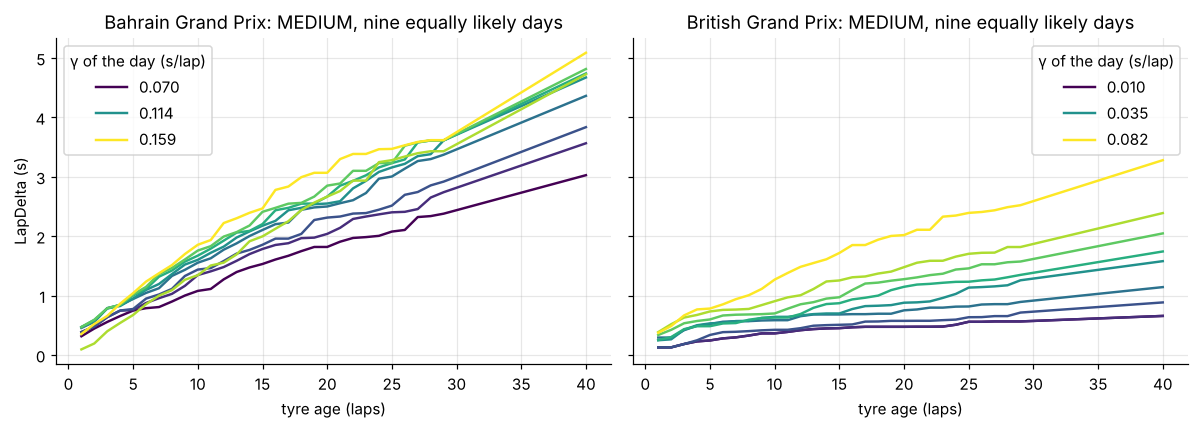

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, gp in zip(axes, ("Bahrain Grand Prix", "British Grand Prix")):
    cfg = eng.resolve_config({"circuit": gp})
    d = eng.degradation_setup(np.array([0]), cfg["total_laps"], 45, cfg)
    for k, g in enumerate(d["deg_nodes"]):
        ax.plot(range(1, 41), d["deg_tables"][k, 0, 1, 1:41, 1], color=plt.cm.viridis(k / 8), lw=1.6,
                label=f"{g:.3f}" if k in (0, 4, 8) else None)
    ax.set_title(f"{gp}: MEDIUM, nine equally likely days"); ax.set_xlabel("tyre age (laps)")
    ax.legend(title="γ of the day (s/lap)")
axes[0].set_ylabel("LapDelta (s)"); plt.tight_layout(); plt.show()

Every curve is a real prediction of the model, so each keeps the guarantee "never faster with age". (A cheaper
trick — one table plus a linear correction — was tried first and broke that guarantee by a few tenths.)

## 7. During the race: update the estimate

The race itself tells us what kind of day it is. `live_estimate` is the regression of step 1 on the laps run **so
far**, with two priors: on $\gamma$ (the circuit's estimate ± $\sigma_{race}$) and on $\varphi$ (fuel burn is
physics, it cannot be far from usual). With Gaussian priors the answer is closed-form: a weighted compromise
between prior and data, like the shrinkage of step 3.

Remember step 1: $\gamma$ and $\varphi$ separate only when tyre age resets. **Until cars have stopped, every tyre
ages one lap per lap** — wear and fuel burn move together and the data alone cannot split them. The estimate should
stay near the prior then, and move once second stints appear. That is what the *design effect* in the code does.

In [18]:
show(degradation.live_estimate)

def live_estimate(laps: pd.DataFrame, prior_mean: float, prior_sd: float,
                  fuel_mean: float = 0.055, fuel_sd: float = LIVE_FUEL_SD,
                  clean_air_gap: float | None = CLEAN_AIR_GAP, design_effect: float | None = None) -> dict:
    """
    Bayesian update of this race's degradation γ with the laps completed so far.

    Same regression as _fit_race, with Gaussian priors on γ (the circuit prior) and φ
    (fuel + evolution). Early in a race every car is on its first set: tyre age and lap
    number move together, the data alone cannot separate γ from φ, and the posterior stays
    near the prior. As cars stop, the data takes over. Closed form (ridge regression with
    a prior mean); the noise variance is the residual variance of the unpenalised fit, inflated
    by a design effect (below).

    Returns {mean, sd, n_laps, prior_mean, prior_sd}.
    """
    out = {"mean": float(prior_mean), "sd": float(prior_sd), "n_laps": 0,
           "prior_mean": float(prior_mean), "prior_sd": float(prior_sd)}
    try:
        g = stint_laps(laps, clean_air_gap=clean_air_gap)
    except Exception:                                  # incomplete live data: keep the prior
        return out
    out["n_laps"] = int(len(g))
    if len(g) < MIN_LIVE_LAPS or g["key"].nunique() < 3:
        return out
    Xd, yd = _design(g)
    keep = Xd.std(axis=0) > 1e-9                       # a compound nobody has used yet
    keep[[0, 3]] = True
    Xd = Xd[:, keep]
    k = Xd.shape[1]
    beta_ols, *_ = np.linalg.lstsq(Xd, yd, rcond=None)
    dof = max(len(yd) - g["key"].nunique() - k, 1)
    s2 = max(float(((yd - Xd @ beta_ols) ** 2).sum() / dof), 0.05 ** 2)
    m0 = np.zeros(k)                                   # prior means: [−φ, compounds…, γ]
    prec = np.full(k, 1 / 2.0 ** 2)                    # compounds: almost flat (sd 2 s)
    m0[0], prec[0] = -fuel_mean, 1 / fuel_sd ** 2
    m0[-1], prec[-1] = prior_mean, 1 / prior_sd ** 2
    # How much to trust the laps. Two things make N laps worth less than N independent ones:
    # laps of one driver are correlated, and — the big one — until cars have stopped, every tyre
    # ages one lap per lap: wear (γ) and fuel burn (φ) move together and only their difference
    # shows. So the noise variance is inflated by a design effect that starts high and comes down
    # as second stints appear (tyre age resets, the lap number does not). The two ends were set so
    # that the 80 % interval holds the race's final γ ~80 % of the time at every stage of the
    # race, leave one race out (see the degradation_by_circuit notebook).
    if design_effect is None:
        s_ = g.sort_values(["key", "LapNumber"])
        new_set = s_.groupby("key")["TyreLife"].diff() < 0                # the tyre got younger: a stop
        on_second = float((new_set.groupby(s_["key"]).cumsum() > 0).mean())
        hi, lo = LIVE_DESIGN_EFFECT
        deff = hi - (hi - lo) * min(on_second / LIVE_STINT2_SHARE, 1.0)
    else:
        deff = design_effect
    s2 = s2 * deff
    A = Xd.T @ Xd / s2 + np.diag(prec)
    cov = np.linalg.inv(A)
    post = cov @ (Xd.T @ yd / s2 + prec * m0)
    sd = float(np.sqrt(min(cov[-1, -1], prior_sd ** 2)))
    out.update(mean=float(np.clip(post[-1], *DEG_RANGE)), sd=sd)
    return out

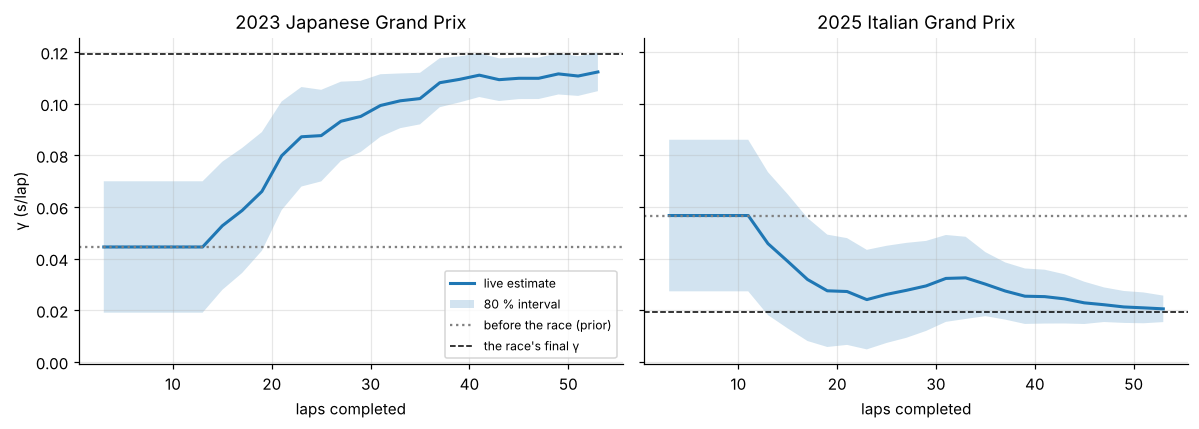

In [19]:
def live_path(season, race):
    r = LAPS[(LAPS.Season == season) & (LAPS.Race == race)]
    name = f"{season} {race}"
    pr = fit_prior(P.drop(name)); c = P.loc[name, "circuit"]
    g0 = pr["circuits"].get(c, pr["global"])
    out = [{"lap": n, **live_estimate(r[r.LapNumber <= n], g0, pr["race_sd"], fuel_mean=pr["fuel"]["global"])}
           for n in range(3, int(r.LapNumber.max()) + 1, 2)]
    return pd.DataFrame(out), P.loc[name, "deg"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (s, r) in zip(axes, ((2023, "Japanese Grand Prix"), (2025, "Italian Grand Prix"))):
    path, true = live_path(s, r)
    ax.plot(path.lap, path["mean"], lw=2, label="live estimate")
    ax.fill_between(path.lap, path["mean"] - 1.28 * path.sd, path["mean"] + 1.28 * path.sd, alpha=0.2, label="80 % interval")
    ax.axhline(path.prior_mean.iloc[0], color="gray", ls=":", label="before the race (prior)")
    ax.axhline(true, color="k", ls="--", lw=1, label="the race's final γ")
    ax.set_title(f"{s} {r}"); ax.set_xlabel("laps completed")
axes[0].set_ylabel("γ (s/lap)"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Is the uncertainty honest?** An interval that says 80 % should contain the truth about 80 % of the time. Leave one
race out (the prior never saw the race), stop at four points of the race, compare with the race's final rate:

In [20]:
rows = []
for name in P.index:
    season, race = int(name[:4]), name[5:]
    r = LAPS[(LAPS.Season == season) & (LAPS.Race == race)]
    pr = fit_prior(P.drop(name)); c = P.loc[name, "circuit"]
    known = c in pr["circuits"]
    g0, sd0 = pr["circuits"].get(c, pr["global"]), (pr["race_sd"] if known else float(np.hypot(pr["race_sd"], pr["circuit_sd"])))
    L = int(r.LapNumber.max())
    for frac in (0.25, 0.4, 0.6, 0.8):
        e = live_estimate(r[r.LapNumber <= int(frac * L)], g0, sd0, fuel_mean=pr["fuel"]["global"])
        rows.append({"distance": f"{frac:.0%}", "err_prior": abs(g0 - P.loc[name, "deg"]), "err_live": abs(e["mean"] - P.loc[name, "deg"]),
                     "inside": abs(P.loc[name, "deg"] - e["mean"]) < 1.2816 * np.hypot(e["sd"], P.loc[name, "deg_se"]),
                     "se": P.loc[name, "deg_se"]})
cal = pd.DataFrame(rows); cal = cal[cal.se < 0.03]
cal.groupby("distance", sort=False).agg(races=("inside", "size"), error_before_race=("err_prior", "mean"),
                                        error_live=("err_live", "mean"), inside_80pct_interval=("inside", "mean")).round(4)

,races,error_before_race,error_live,inside_80pct_interval
distance,,,,
25%,31,0.0236,0.0239,0.7742
40%,31,0.0236,0.0172,0.7742
60%,31,0.0236,0.0107,0.8387
80%,31,0.0236,0.0070,0.8710


**Reading it.** At a quarter distance the estimate is still the prior (nobody has stopped: nothing to learn from).
By 40 % the error is clearly down, by 60 % by about half — and the 80 % intervals contain the truth about
80 % of the time at every stage. Careful with that last claim: the constants of the design effect were *chosen* on
these races to get there, so it is a fit, not an independent test. A first version that trusted early laps as if
they were independent was *worse than the prior* at 25 % distance.

## 8. Validate the decision: one stop or two?

The reason for all this was a decision. `python -m tools.backtest --stops` asks the Stint Optimizer, for each
race — with models, prior and pit loss fitted **without that race** — whether two stops beat one on a clear
track, and compares with what the finishers did. Three levels of knowledge of the day: before the race (circuit
prior), at 40 % distance (live estimate), and with the whole race (hindsight — the ceiling).

In [21]:
show(stint_optimizer.best_strategies)

def best_strategies(total_laps: int, team: str | int, config: dict, pit_cost: float = PIT_COST_GREEN,
                    max_stops: int = 3, min_stint: int = MIN_STINT, compounds=("SOFT", "MEDIUM", "HARD"),
                    deg_rate: float | None = None, costs: np.ndarray | None = None) -> pd.DataFrame:
    """
    The fastest strategy for each number of stops (1…max_stops): every combination of pit laps
    (stints of at least `min_stint` laps) × every legal compound order. Columns: Stops, Strategy,
    Pit laps, Total Δ (s) (tyre time lost + pit stops), Gap to best (s), and the raw
    `pit_laps` / `compounds` lists.
    Each lap of tyre age costs the same on any race lap for V3+ models (fuel is corrected out), so
    two orders of the same compounds tie; the softer start is listed.
    """
    L = total_laps
    cost = stint_costs(L, team, config, deg_rate) if costs is None else costs
    out = []
    for stops in range(1, max_stops + 1):
        pits = np.array([p for p in combinations(range(min_stint, L - min_stint + 1), stops)
                         if all(b - a >= min_stint for a, b in zip(p, p[1:]))], dtype=int).reshape(-1, stops)
        if not len(pits):
            continue
        starts = np.column_stack([np.ones(len(pits), dtype=int), pits + 1])          # first lap of each stint
        lengths = np.diff(np.column_stack([np.zeros(len(pits), dtype=int), pits, np.full(len(pits), L)]), axis=1)
        best = (np.inf, None, None)
        for seq in _sequences(stops + 1, compounds):
            total = sum(cost[cmp, starts[:, k], lengths[:, k]] for k, cmp in enumerate(seq)) + stops * pit_cost
            i = int(np.argmin(total))
            if total[i] < best[0] - 1e-9:
                best = (float(total[i]), seq, pits[i])
        total, seq, laps = best
        out.append({"Stops": stops, "Strategy": " → ".join(COMPOUND_NAMES[c] for c in seq),
                    "Pit laps": ", ".join(f"L{p}" for p in laps), "Total Δ (s)": round(total, 2),
                    "pit_laps": [int(p) for p in laps], "compounds": [COMPOUND_NAMES[c] for c in seq]})
    df = pd.DataFrame(out)
    df["Gap to best (s)"] = (df["Total Δ (s)"] - df["Total Δ (s)"].min()).round(2)
    return df

34 races (Monaco 2025 left out: two stops were compulsory) · the majority stopped twice or more in 15 · 'always one stop' agrees with the field in 56%
                        AUC AUC 95 % interval AUC without Bahrain agrees with the field two-stop races found … outside Bahrain
V3.1, before the race  0.59         0.38–0.79                0.55                  0.59                 0.13              0.18
V3.2, before the race  0.74         0.55–0.89                0.65                  0.65                 0.27              0.00
V3.2, at 40 % distance 0.84         0.68–0.97                0.78                  0.68                 0.33              0.18
V3.2, whole race known 0.86         0.70–0.96                0.80                  0.76                 0.47              0.27

Pre-race probability of two stops — Brier score 0.260 vs 0.247 for the base rate (lower is better; V3.1: 0.412)

Bahrain, two-stop advantage (s; > 0 = two stops faster):
        V3.1 before  V3.2 before  at 40 %  

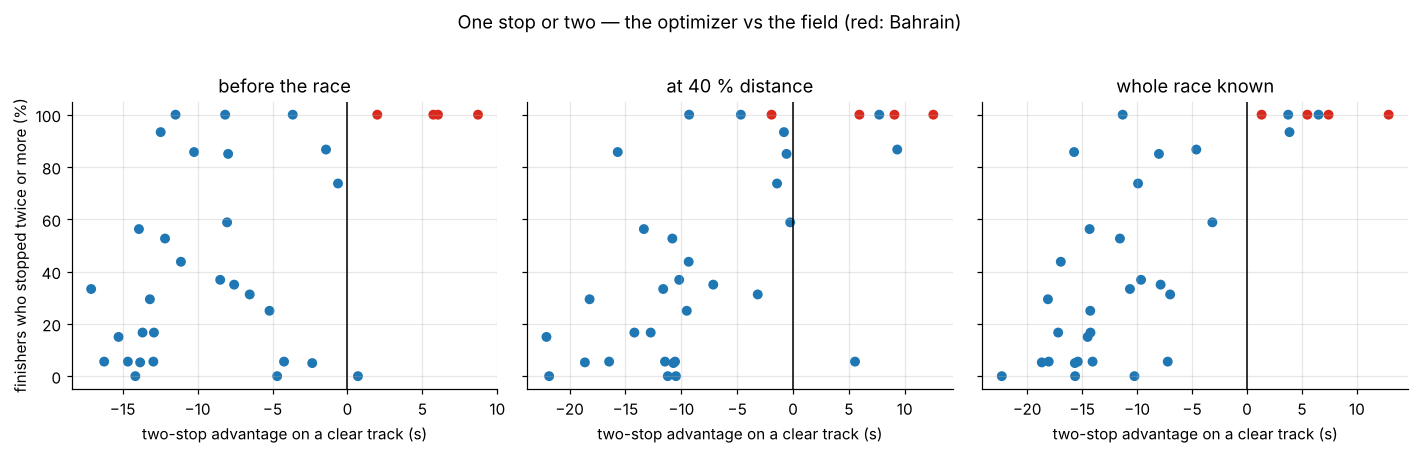

In [22]:
import json
from tools import backtest
mdir = os.path.join(ROOT, "models")
stops = pd.DataFrame(json.load(open(os.path.join(mdir, "backtest_report_stops.json")))["races"])   # python -m tools.backtest --stops
v31 = pd.DataFrame(json.load(open(os.path.join(mdir, "backtest_report_stops_v31.json")))["races"])  # same check, V3.1 lap model
S32, S31 = backtest.summarise_stop_counts(stops), backtest.summarise_stop_counts(v31)
print(f"{S32['races']} races (Monaco 2025 left out: two stops were compulsory) · the majority stopped twice or more in "
      f"{S32['real_two_stop_races']} · 'always one stop' agrees with the field in {S32['always_one_stop_agree']:.0%}")
rows = {"V3.1, before the race": S31["before"], "V3.2, before the race": S32["before"],
        "V3.2, at 40 % distance": S32["live"], "V3.2, whole race known": S32["hindsight"]}
summary = pd.DataFrame({k: {"AUC": v["auc"], "AUC 95 % interval": f"{v['auc_ci95'][0]:.2f}–{v['auc_ci95'][1]:.2f}",
                            "AUC without Bahrain": v["auc_without_bahrain"], "agrees with the field": v["agree"],
                            "two-stop races found": v["two_stop_races_found"],
                            "… outside Bahrain": v["two_stop_found_without_bahrain"]} for k, v in rows.items()}).T
print(summary.to_string(float_format=lambda x: f"{x:.2f}"))
print(f"\nPre-race probability of two stops — Brier score {S32['brier_p_two']:.3f} vs {S32['brier_base_rate']:.3f} for the base rate "
      f"(lower is better; V3.1: {S31['brier_p_two']:.3f})")
bah = stops[stops.race == "Bahrain Grand Prix"].set_index("season")
print("\nBahrain, two-stop advantage (s; > 0 = two stops faster):")
print(pd.DataFrame({"V3.1 before": v31[v31.race == "Bahrain Grand Prix"].set_index("season").gap_s, "V3.2 before": bah.gap_s,
                    "at 40 %": bah.gap_live_s, "whole race": bah.gap_final_s}).round(1).to_string())
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
keep = ~stops.apply(lambda r: (int(r.season), r.race) in backtest.MANDATED_STOPS, axis=1)
for ax, (name, col) in zip(axes, {"before the race": "gap_s", "at 40 % distance": "gap_live_s", "whole race known": "gap_final_s"}.items()):
    d = stops[keep]
    ax.scatter(d[col], d.real_two * 100, c=np.where(d.race == "Bahrain Grand Prix", "#DA291C", "#1f77b4"), s=30)
    ax.axvline(0, color="k", lw=1); ax.set_title(name); ax.set_xlabel("two-stop advantage on a clear track (s)")
axes[0].set_ylabel("finishers who stopped twice or more (%)")
plt.suptitle("One stop or two — the optimizer vs the field (red: Bahrain)", y=1.02); plt.tight_layout(); plt.show()

## Findings

- **Bahrain is a two-stop race again — in all four seasons, before the race, never having seen it** (two stops
  faster by 2 to 9 s). With the V3.1 lap model the same test said one stop was faster by 8–11 s in all four.
  One wobble: for Bahrain 2024 the live estimate at 40 % distance tips to one stop (−1.9 s) before the whole race
  brings it back (+1.3 s).
- **That is most of what the pre-race call gained.** Before the race the tool says "two stops" for five races: the
  four Bahrains and Monaco 2024 (wrong: nobody passes there). Outside Bahrain it finds none of the eleven two-stop
  races (V3.1 found two of them — and none of the Bahrains), and its probability is no better than the base rate (Brier 0.260 vs 0.247). Honest reading: V3.2 fixed the
  circuit it was aimed at; before a race it cannot yet tell the other two-stop races apart.
- **Knowing the day helps the ranking.** The AUC of the two-stop advantage goes 0.74 before the race → 0.84 at
  40 % distance → 0.86 with the whole race (V3.1 before the race: 0.59), and without Bahrain 0.65 → 0.78 → 0.80.
  With 34 races the 95 % intervals are wide (±0.15) and overlap: the direction is consistent, the size is not
  pinned down. "Always one stop" agrees with the field in 56 % of races; the tool in 65 % / 68 % / 76 %.
- **The engine is unchanged, not better.** Leave one race out, from 40 % distance, the same 35 races: Spearman ρ
  0.893 (V3.1: 0.892), position error 1.47 (1.51), 80 % intervals contain the real position 79.8 % of the time
  (78.8 %), and it ranks better than "the order stays the same" in 25 races (V3.1: 26). The tyre fix did not
  cost the engine anything; it did not buy it much either.
- **What is still wrong.** The dots sit to the *left* of zero: the tool leans to one stop by several seconds.
  Even with the whole race known it finds only 3 of the 11 two-stop races outside Bahrain. Reasons the tyre model
  cannot see: on a one-stop, drivers *manage* the tyres (they are slower from lap one, which looks like a
  long-lived tyre in the data); teams avoid the risk of a tyre falling off a cliff; and Safety Cars hand out cheap
  stops. So the dashboard says to read a small margin as a toss-up.
- **Two caveats on "calibrated".** The live estimate's design-effect constants and the engine's `RACE_FORM_STD`
  were *chosen* to give 80 % coverage on these same races. The priors and models are leave-one-out; those few
  constants are not, so the coverage numbers are a fit, not a test.
- **Monaco** is the reminder of what "clear track" leaves out: tyre life says stop, track position says never.

## What to remember

1. Check a model on the quantity the decision uses. MAE did not show the problem; the slope did.
2. When groups have few observations, shrink them — and when the group explains only half of the variance, model
   the other half as uncertainty instead of pretending it away.
3. A feature you only know afterwards can still be used: train with the truth, serve with your best estimate **and
   its uncertainty**.
4. Calibrate uncertainties against held-out outcomes (80 % must mean 80 %).
5. Validate decisions, not only predictions — and report what is still wrong.